<a href="https://colab.research.google.com/github/Ksenia-Savich/cooperative/blob/main/%D0%B2%D0%B8%D0%B7%D1%83%D0%B0%D0%BB%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D1%8F_virtual_assis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Установка razdel: ее нет в Colab по умолчанию
!pip install razdel

In [2]:
# Регулярные выражения потребуются для очистки текста
import re

# Библиотека razdel потребуется для разбияния текста на предложения
# перед отправкой в нейросеть
from razdel import sentenize

# Без torch невозможна работа с нейросетями
import torch

# Библиотека transformers нужна для работы с нейросетями-трансформерами,
# которые мы будем использовать для анализа тональности
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Библиотека matplotlib позволит построить графики кривых тональности
from matplotlib import pyplot as plt

# Фильтр Савицкого-Голея понадобится нам для обработки результатов,
# которая будет описана позже
from scipy.signal import savgol_filter

In [12]:
import pandas as pd
import numpy as np
import seaborn as sns

In [21]:
df = pd.read_csv("processed_dataset.csv", encoding="utf-8-sig")
display(df.head(10))

,user_id,category,text,response_time,quality_rating,device,task_successful,label,text_ready,tokens,text_lemmas
0,fc0304e8-55ab-42fd-84bb-e3df6b62f606,новости,Расскажи последние новости экономики,1.47,4,смарт-часы,True,True,NaN,"['рассказать', 'последний', 'новость', 'эконом...",рассказать последний новость экономика
1,d0c1993d-32e2-4a52-af6c-096a34b5305f,погода,Какая погода сегодня в Москве?,4.88,6,умная колонка,False,False,погода сегодня москве,"['погода', 'сегодня', 'москва']",погода сегодня москва
2,adc1ee79-b43c-441d-8ff2-838ec28ab41c,навигация,Как доехать до центра?,6.96,7,планшет,True,True,NaN,"['доехать', 'центр']",доехать центр
3,93472d1d-c987-4990-8827-d22ccf9ba92e,финансы,Проверь баланс карты,0.68,7,ноутбук,True,True,проверь баланс карты,"['проверить', 'баланс', 'карта']",проверить баланс карта
4,24a776f7-c3bb-4109-a1ef-fe8acec6e63c,покупки,Покажи акции на одежду,0.21,10,смартфон,True,True,покажи акции одежду,"['показать', 'акция', 'одежда']",показать акция одежда
5,92501487-c9e8-495d-8da1-cb235a97d7be,покупки,Покажи акции на одежду,6.30,6,умная колонка,False,False,покажи акции одежду,"['показать', 'акция', 'одежда']",показать акция одежда
6,04b44532-04ed-4293-a89e-0b5595f79bb1,навигация,Построй маршрут до ближайшей аптеки,1.48,7,планшет,False,False,построй маршрут ближайшей аптеки,"['построить', 'маршрут', 'близкий', 'аптека']",построить маршрут близкий аптека
7,34699609-8255-44ea-b0c7-f9e1da1c0242,погода,Прогноз погоды на завтра в Санкт-Петербурге,2.34,5,смартфон,True,True,прогноз погоды завтра санктпетербурге,"['прогноз', 'погода', 'завтра', 'санктпетербург']",прогноз погода завтра санктпетербург
8,721f4273-a606-4cd9-904c-e477941aaedf,покупки,Где купить ноутбук?,10.33,10,умная колонка,True,True,купить,"['купить', 'ноутбук']",купить ноутбук
9,63ada0de-808a-45c5-9356-665b2fb482a9,навигация,Сколько времени до аэропорта?,0.21,8,смартфон,False,False,времени аэропорта,"['сколько', 'время', 'аэропорт']",сколько время аэропорт


In [8]:
# настройка стиля
plt.style.use('ggplot')

базовые графики

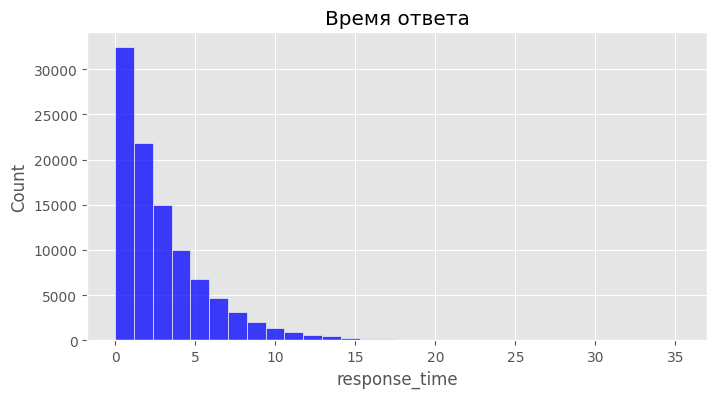

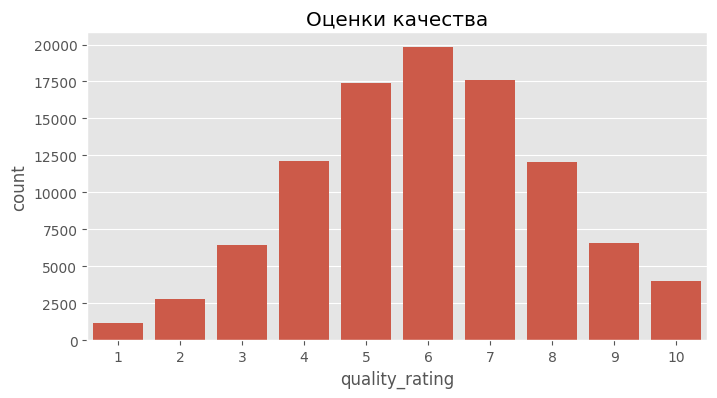

In [33]:
# график времени ответа
plt.figure(figsize=(8, 4))
sns.histplot(df['response_time'], bins=30, color='blue')
plt.title('Время ответа')
plt.show()

# график оценок
plt.figure(figsize=(8, 4))
sns.countplot(x='quality_rating', data=df)
plt.title('Оценки качества')
plt.show()

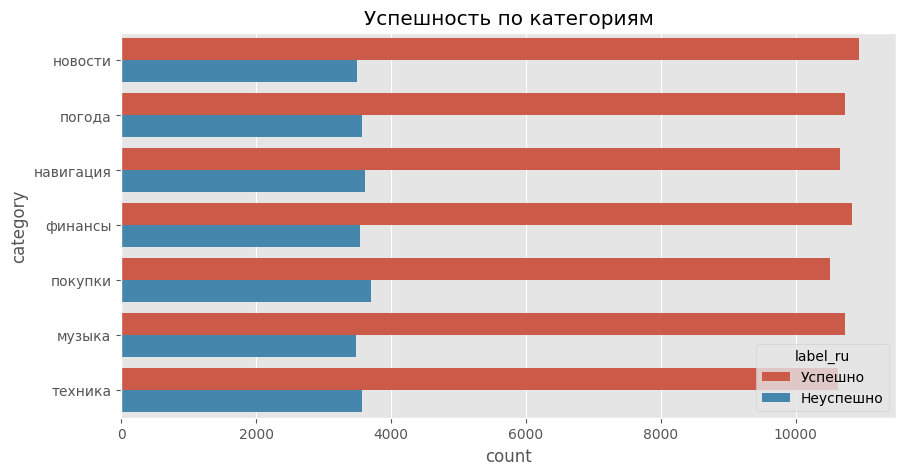

In [44]:
# берем 10 самых популярных категорий
top_10 = df['category'].value_counts().head(10).index
df_top = df[df['category'].isin(top_10)]

# пересоздаем колонку, если она потерялась
df_top['label_ru'] = df_top['label'].replace({True: 'Успешно', False: 'Неуспешно'})

# рисуем
plt.figure(figsize=(10, 5))
sns.countplot(y='category', hue='label_ru', data=df_top)
plt.title('Успешность по категориям')
plt.show()

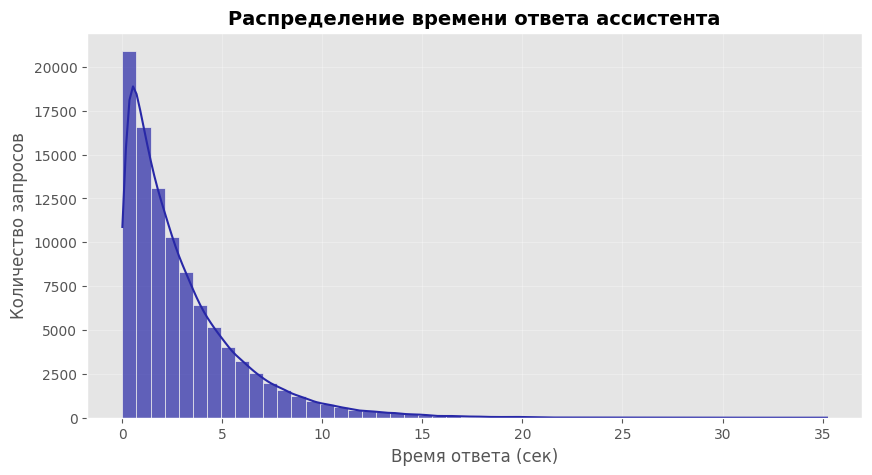

In [32]:
# 1.1 распределение времени ответа (аналог гистограммы)
plt.figure(figsize=(10, 5))
sns.histplot(df['response_time'], bins=50, kde=True, color='#2828a7', alpha=0.7)
plt.title('Распределение времени ответа ассистента', fontsize=14, fontweight='bold')
plt.xlabel('Время ответа (сек)')
plt.ylabel('Количество запросов')
plt.grid(True, alpha=0.3)
plt.show()

/tmp/ipykernel_801/957502330.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='quality_rating', data=df, palette='viridis')


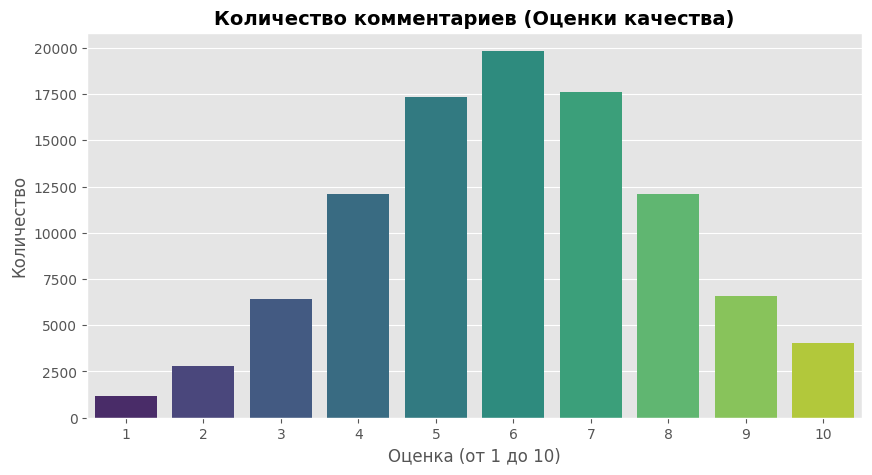

In [14]:
# 1.2 распределение оценок качества (аналог графика Review Stars)
plt.figure(figsize=(10, 5))
ax = sns.countplot(x='quality_rating', data=df, palette='viridis')
ax.set_title('Количество комментариев (Оценки качества)', fontsize=14, fontweight='bold')
ax.set_xlabel('Оценка (от 1 до 10)')
ax.set_ylabel('Количество')
plt.show()


In [39]:
# пересоздаем колонку с красивыми названиями для графика
df['label_text'] = df['label'].astype(str).replace({'True': 'Успешно', 'False': 'Неуспешно'})

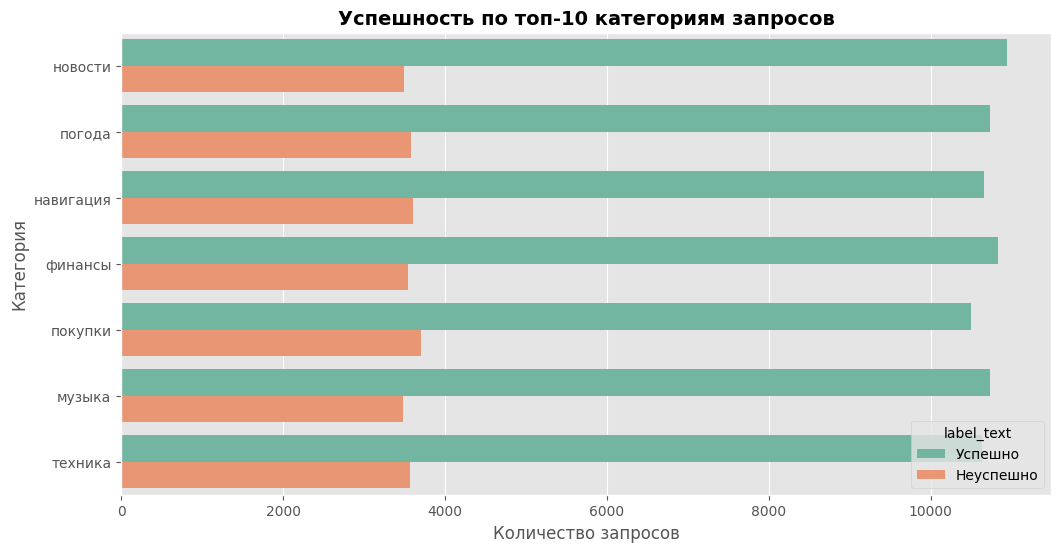

In [23]:
# 1.3 успешность по категориям (Топ-10)
top_categories = df['category'].value_counts().head(10).index
df_top = df[df['category'].isin(top_categories)]

plt.figure(figsize=(12, 6))
sns.countplot(y='category', hue='label_text', data=df_top, palette='Set2')
plt.title('Успешность по топ-10 категориям запросов', fontsize=14, fontweight='bold')
plt.xlabel('Количество запросов')
plt.ylabel('Категория')
plt.show()

облако слов

In [48]:
# берем тексты успешных запросов
success_text = ' '.join(df[df['label'] == True]['text'].astype(str).values)

In [49]:
!pip install wordcloud
from wordcloud import WordCloud

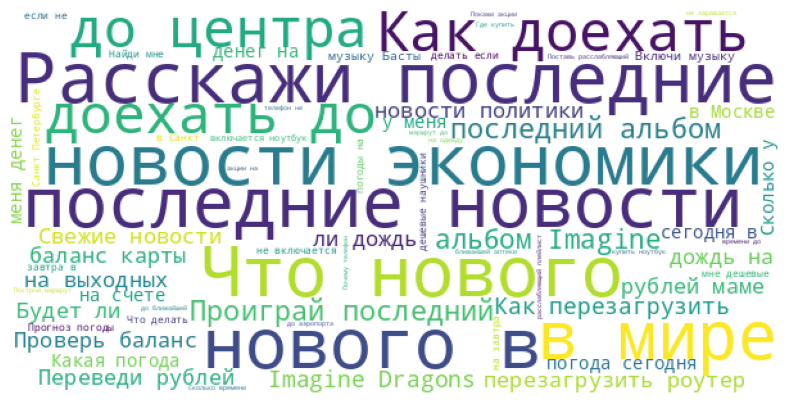

In [51]:
# рисуем облако
cloud = WordCloud(width=600, height=300, background_color='white').generate(success_text)

plt.figure(figsize=(10, 5))
plt.imshow(cloud)
plt.axis('off') # убираем оси
plt.show()

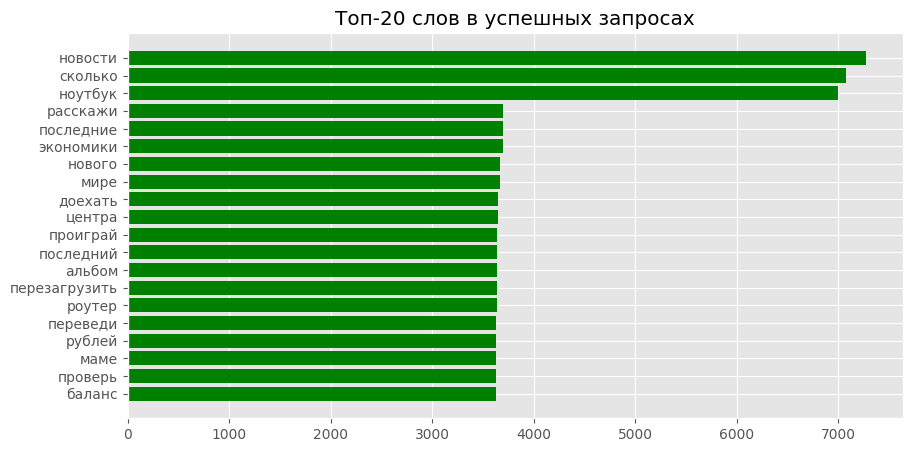

In [53]:
# ищем все слова от 4 букв и считаем их
words = re.findall(r'\b[а-яё]{4,}\b', success_text.lower())
top_words = Counter(words).most_common(20)

# разделяем на названия слов и их количество
names = [word for word, count in top_words]
counts = [count for word, count in top_words]

# рисуем
plt.figure(figsize=(10, 5))
plt.barh(names, counts, color='green')
plt.gca().invert_yaxis() # Самое частое слово сверху
plt.title('Топ-20 слов в успешных запросах')
plt.show()

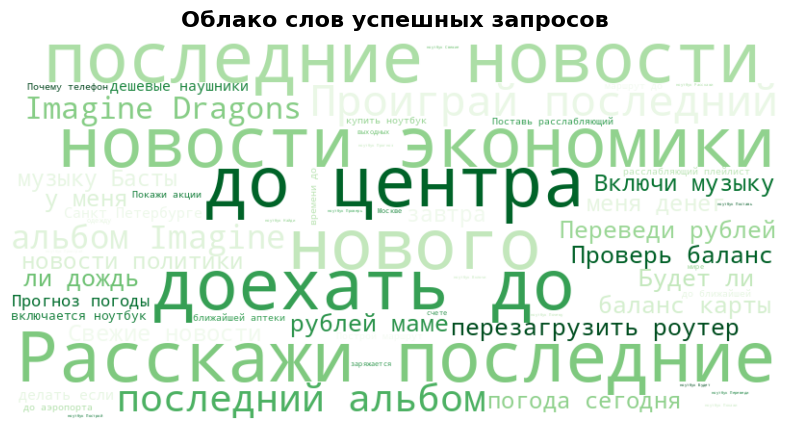

In [35]:

# 2.1 облако слов для позитивных отзывов
wordcloud = WordCloud(
    width=800, height=400, background_color='white', colormap='Greens',
    max_words=100,
    stopwords=['это', 'очень', 'все', 'так', 'что', 'который', 'свой', 'и', 'то', 'а', 'на', 'не', 'но', 'за', 'как', 'к', 'по', 'я', 'мне', 'с', 'в', 'где', 'сколько', 'какой', 'какая', 'есть']
).generate(success_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('Облако слов успешных запросов', fontsize=16, fontweight='bold')
plt.axis('off')
plt.show()

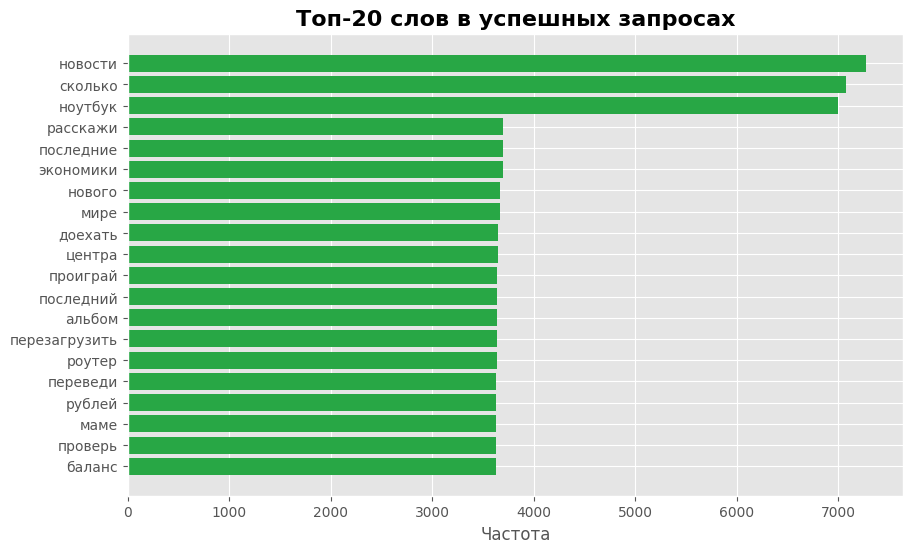

In [28]:
# 2.2 топ 20 слов в позитивных отзывах (регулярка ищет слова от 4 букв)
from collections import Counter
import re
words = re.findall(r'\b[а-яё]{4,}\b', success_text.lower())
word_freq = Counter(words)
top_words = word_freq.most_common(20)

plt.figure(figsize=(10, 6))
plt.barh([w[0] for w in top_words], [w[1] for w in top_words], color='#28A745')
plt.title('Топ-20 слов в успешных запросах', fontsize=16, fontweight='bold')
plt.xlabel('Частота')
plt.gca().invert_yaxis() # Чтобы самое частое слово было сверху
plt.show()

анализ взаимосвязей и длины текста

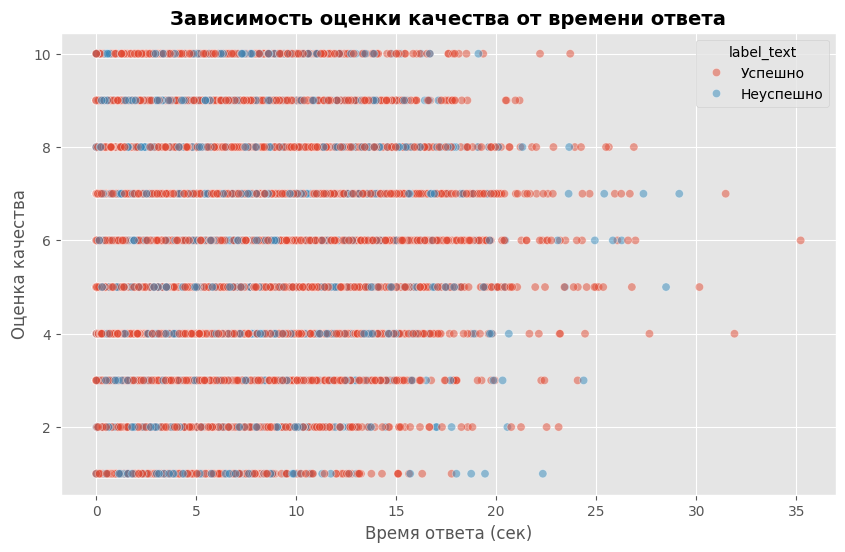

In [29]:
# 3.1 зависимость оценки качества от времени ответа (аналог scatter plot)
plt.figure(figsize=(10, 6))
sns.scatterplot(x='response_time', y='quality_rating', hue='label_text', data=df, alpha=0.5)
plt.title('Зависимость оценки качества от времени ответа', fontsize=14, fontweight='bold')
plt.xlabel('Время ответа (сек)')
plt.ylabel('Оценка качества')
plt.show()

/tmp/ipykernel_801/2645227609.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label_text', y='word_count', data=df, palette='viridis')


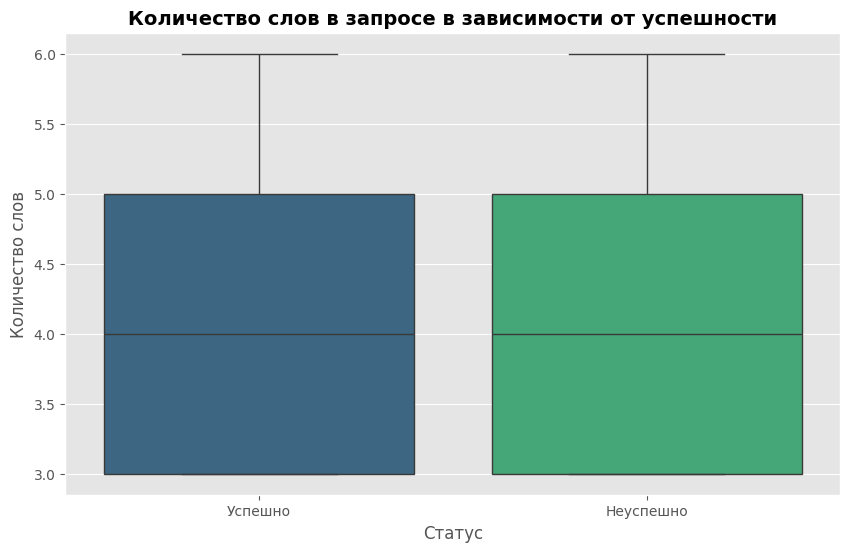

In [30]:
# 3.2 длина текста vs успешность (аналог boxplot)
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))
df['review_len'] = df['text'].apply(lambda x: len(str(x)))

plt.figure(figsize=(10, 6))
sns.boxplot(x='label_text', y='word_count', data=df, palette='viridis')
plt.title('Количество слов в запросе в зависимости от успешности', fontsize=14, fontweight='bold')
plt.xlabel('Статус')
plt.ylabel('Количество слов')
plt.show()

тепловая карта

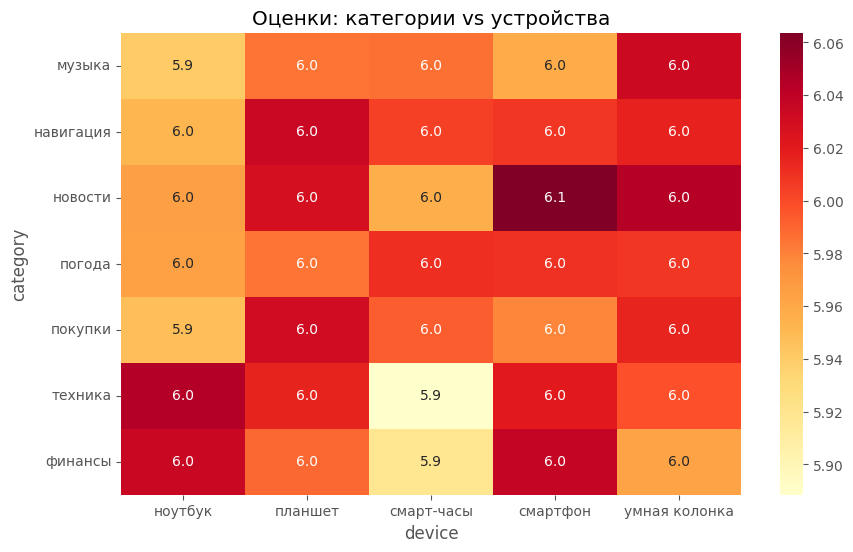

In [56]:
# создаем таблицу: строки - категории, столбцы - устройства, значения - средняя оценка
table = df.pivot_table(values='quality_rating', index='category', columns='device', aggfunc='mean')

# рисуем
plt.figure(figsize=(10, 6))
sns.heatmap(table, cmap='YlOrRd', annot=True, fmt='.1f')
plt.title('Оценки: категории vs устройства')
plt.show()

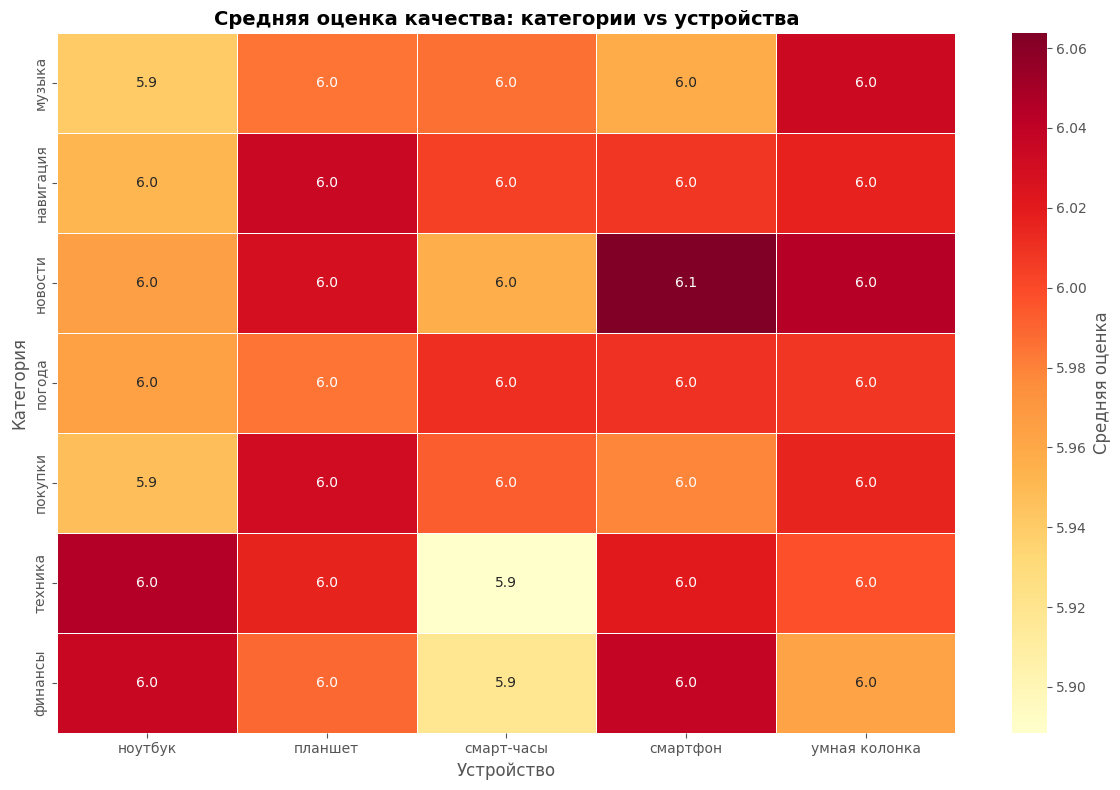

In [31]:
# средняя оценка качества по категориям и устройствам
pivot_rating = df.pivot_table(values='quality_rating', index='category', columns='device', aggfunc='mean')

plt.figure(figsize=(12, 8))
sns.heatmap(pivot_rating, cmap='YlOrRd', annot=True, fmt='.1f',
            cbar_kws={'label': 'Средняя оценка'}, linewidths=0.5)
plt.title('Средняя оценка качества: категории vs устройства', fontsize=14, fontweight='bold')
plt.xlabel('Устройство')
plt.ylabel('Категория')
plt.tight_layout()
plt.show()